

<h2 style= "color: #001c80; text-align: left; font-weight: bold;">
Wine Classification Using K-Nearest Neighbors and PCA
</h2>

<h3 style= "color: #1F5FBF; text-align: left; font-weight: bold;">
1. Business Understanding
</h3>

A premium wine distributor needs an automated system for classifying wines based on their chemical properties. Manual identification is slow and subjective, and misclassified bottles lead to inventory errors and quality-control problems. The three classes in the data are wine cultivars (grape varieties) grown in the same region of Italy, each identified from lab measurements of 13 chemical attributes.

The objective of this analysis is to develop a machine learning classification model that can accurately identify wine classes from their chemical characteristics.

The project will use Principal Component Analysis (PCA) for dimensionality reduction and K-Nearest Neighbors (KNN) for classification. Hyperparameter tuning will then be used to identify an optimal model configuration.

**Success criteria**
- Test accuracy of at least 95%, with every class reaching a comparable precision and recall (no class is sacrificed for overall accuracy)
- A cross-validated estimate that supports the test result, since the test set is small (36 samples, so one error is about 2.8%)
- A tuning procedure free of data leakage, so reported performance is a trustworthy estimate of real-world behaviour

**Stakeholders:** distributor's inventory and quality-control teams (users of the predictions), the sommelier / lab staff (who validate the results) and management (who decide on adoption).

**Assumptions and constraints:** the data is a small, clean benchmark (178 samples, no missing values); new wines are assumed to come from the same three cultivars and to be measured with the same lab procedure; predictions are decision support and uncertain cases should be reviewed by an expert.

In [1]:
# Import of libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load in the data
wine_df = pd.read_csv("wine.csv")

In [2]:
# data inspection
wine_df.shape

(178, 14)

In [3]:
wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
wine_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [5]:
wine_df.columns

Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline', 'target'],
      dtype='object')

<h4 style= "color: #519de9; text-align: left; font-weight: bold;">
Initial Observations
</h4>

- The dataset contains 178 wine samples and 14 columns
- There are 13 numerical predictor features representing different chemical properties of the wines, such as `alcohol`, `flavanoids`, `color_intensity` and `proline`
- The `target` column is the dependent variable and represents the wine class (cultivar) to be predicted. It has three classes: 0, 1 and 2
- All predictor variables are stored as floating-point numbers, while the target is stored as an integer
- There are no missing values based on the initial inspection
- The features have considerably different numerical scales. For example, `proline` is measured in the hundreds and thousands, while `hue` is close to 1. Because both PCA and K-Nearest Neighbors are sensitive to scale, the features will need to be standardized during data preparation

##### Missing Values

We check for missing values if any observations require removal or imputation before modelling.

In [6]:
wine_df.isnull().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

In [7]:
#check for duplicate records
wine_df.duplicated().sum()

np.int64(0)

##### Target Examination

The distribution of the target variable is examined to check whether the wine classes are balanced. `value_counts()` gives the number of samples in each class, and `normalize=True` converts these counts into proportions, which are multiplied by 100 to give percentages.

- Class 0: 59 samples (about 33.1%)
- Class 1: 71 samples (about 39.9%)
- Class 2: 48 samples (about 27.0%)

Class 1 is the largest and Class 2 the smallest, but the difference is modest. There is no severe class imbalance, so accuracy remains a meaningful metric. A stratified train-test split will later preserve these proportions in both the training and test sets.

In [8]:
wine_df["target"].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

In [9]:
wine_df["target"].value_counts(normalize=True) * 100

target
1    39.887640
0    33.146067
2    26.966292
Name: proportion, dtype: float64

In [10]:
# descriptive stats
wine_df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


<h4 style= "color: #51ace9; text-align: left; font-weight: bold;">
Data Quality Findings
</h4> 

The dataset contains no missing values and no duplicate observations. Therefore, no records need to be removed or imputed at this stage

The target variable contains three wine classes:
- Class 0: 59 samples
- Class 1: 71 samples
- Class 2: 48 samples

Although the classes are not perfectly balanced, there is no severe class imbalance. A stratified train-test split will later be used to preserve these class proportions when preparing the data for modelling

<h4 style= "color: #51aae9; text-align: left; font-weight: bold;">
2.2. Exploratory Data Analysis
</h4> 

<h5 style= "color: #51aae9; text-align: left; font-weight: bold;">
2.2.1. Plot Target Distribution
</h5>

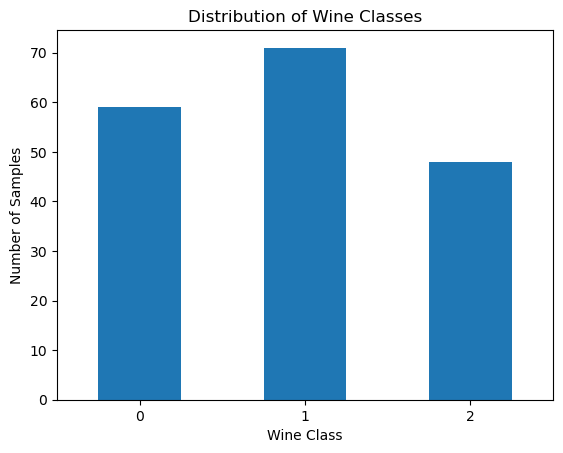

In [11]:
wine_df["target"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Wine Classes")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

<h5 style= "color: #51bee9; text-align: left; font-weight: bold;">
2.2.2. Plot Feature Distribution
</h5>

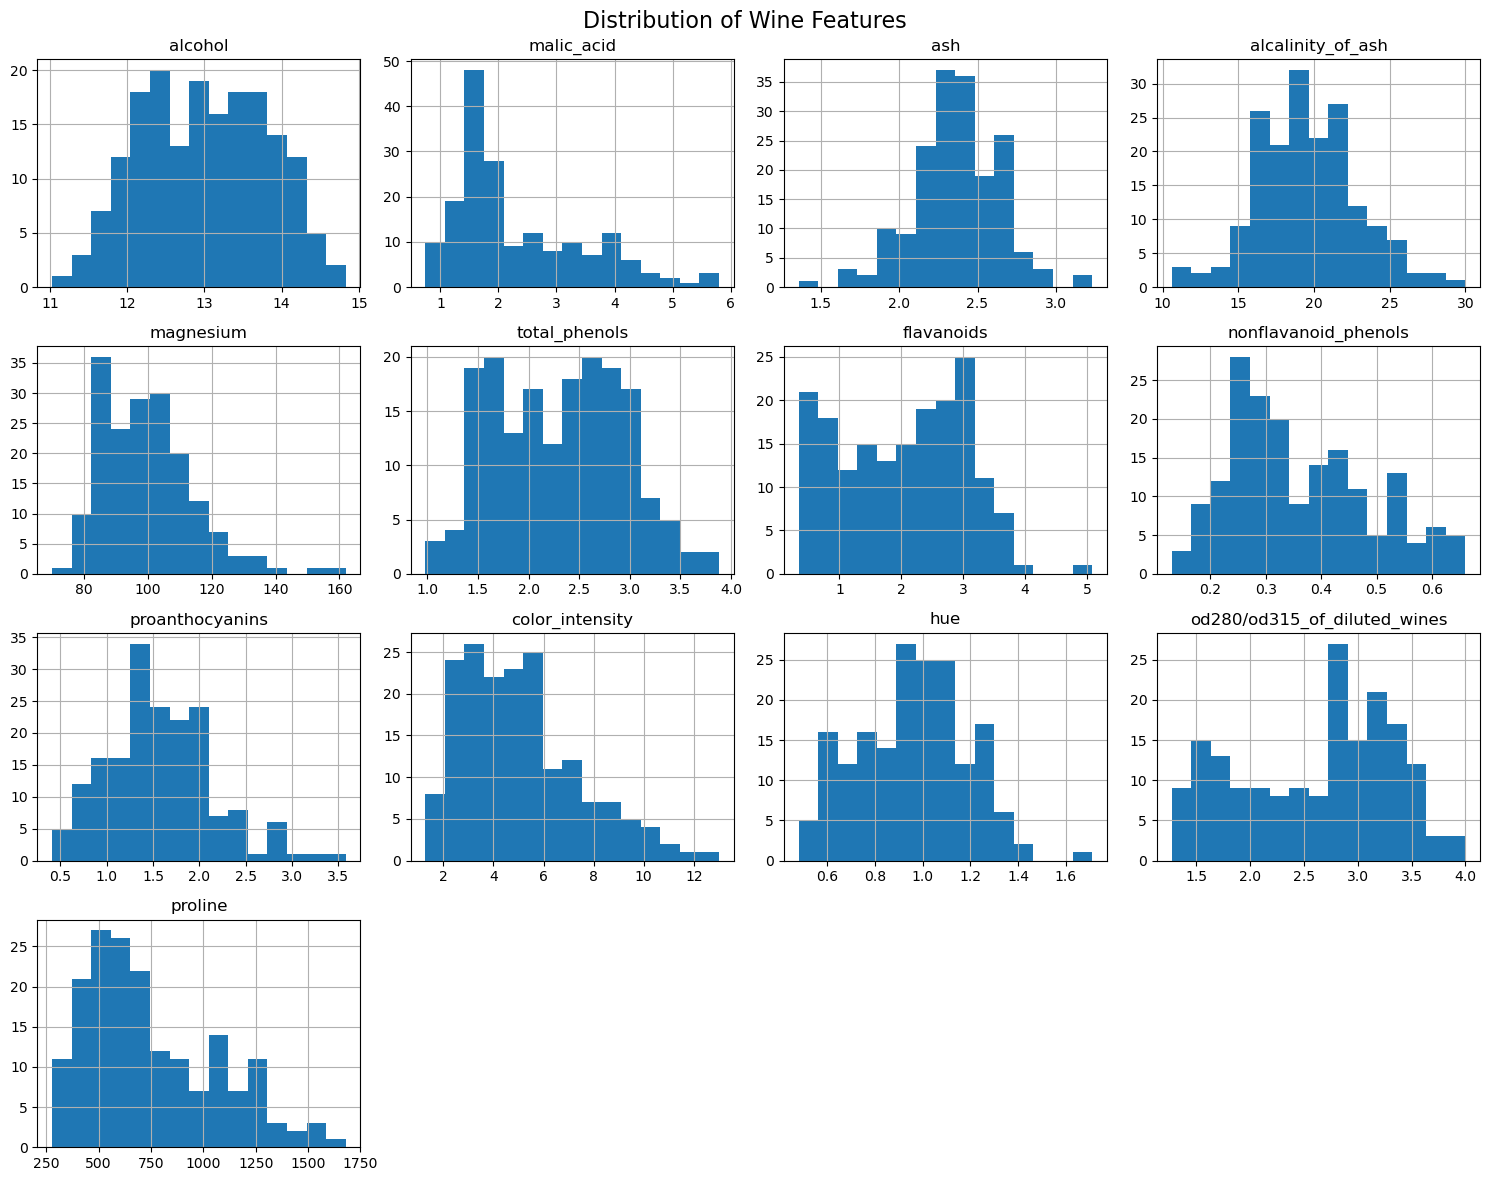

In [12]:
wine_df.drop(columns="target").hist(
    figsize=(15, 12),
    bins=15
)

plt.suptitle("Distribution of Wine Features", fontsize=16)
plt.tight_layout()
plt.show()

<h5 style= "color: #51aae9; text-align: left; font-weight: bold;">
2.2.3. Feature Comparison Across Wine Classes
</h5>

This is done to check whether the distributions differ substantially between classes, that's evidence that these chemical properties may contain useful information for classification.

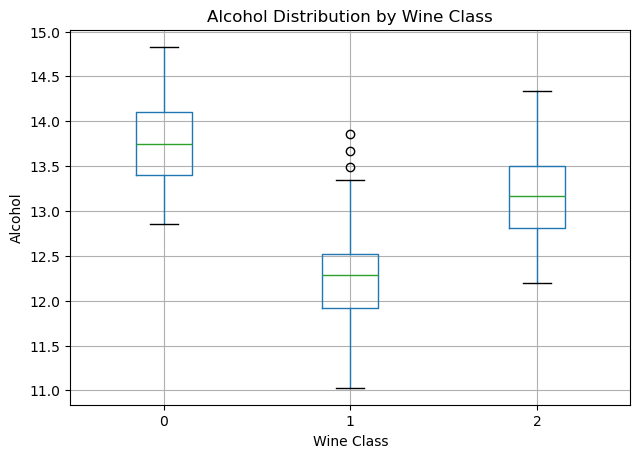

In [13]:
wine_df.boxplot(
    column="alcohol",
    by="target",
    figsize=(7, 5)
)

plt.title("Alcohol Distribution by Wine Class")
plt.suptitle("")
plt.xlabel("Wine Class")
plt.ylabel("Alcohol")
plt.show()

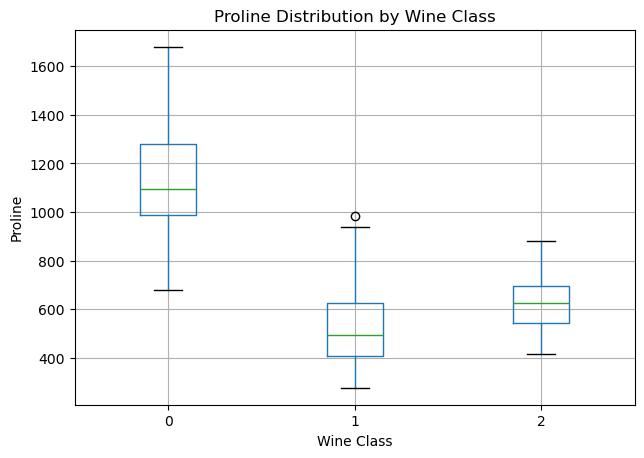

In [14]:
wine_df.boxplot(
    column="proline",
    by="target",
    figsize=(7, 5)
)

plt.title("Proline Distribution by Wine Class")
plt.suptitle("")
plt.xlabel("Wine Class")
plt.ylabel("Proline")
plt.show()

<h5 style= "color: #51a2e9; text-align: left; font-weight: bold;">
2.2.4. Correlation Matrix
</h5>

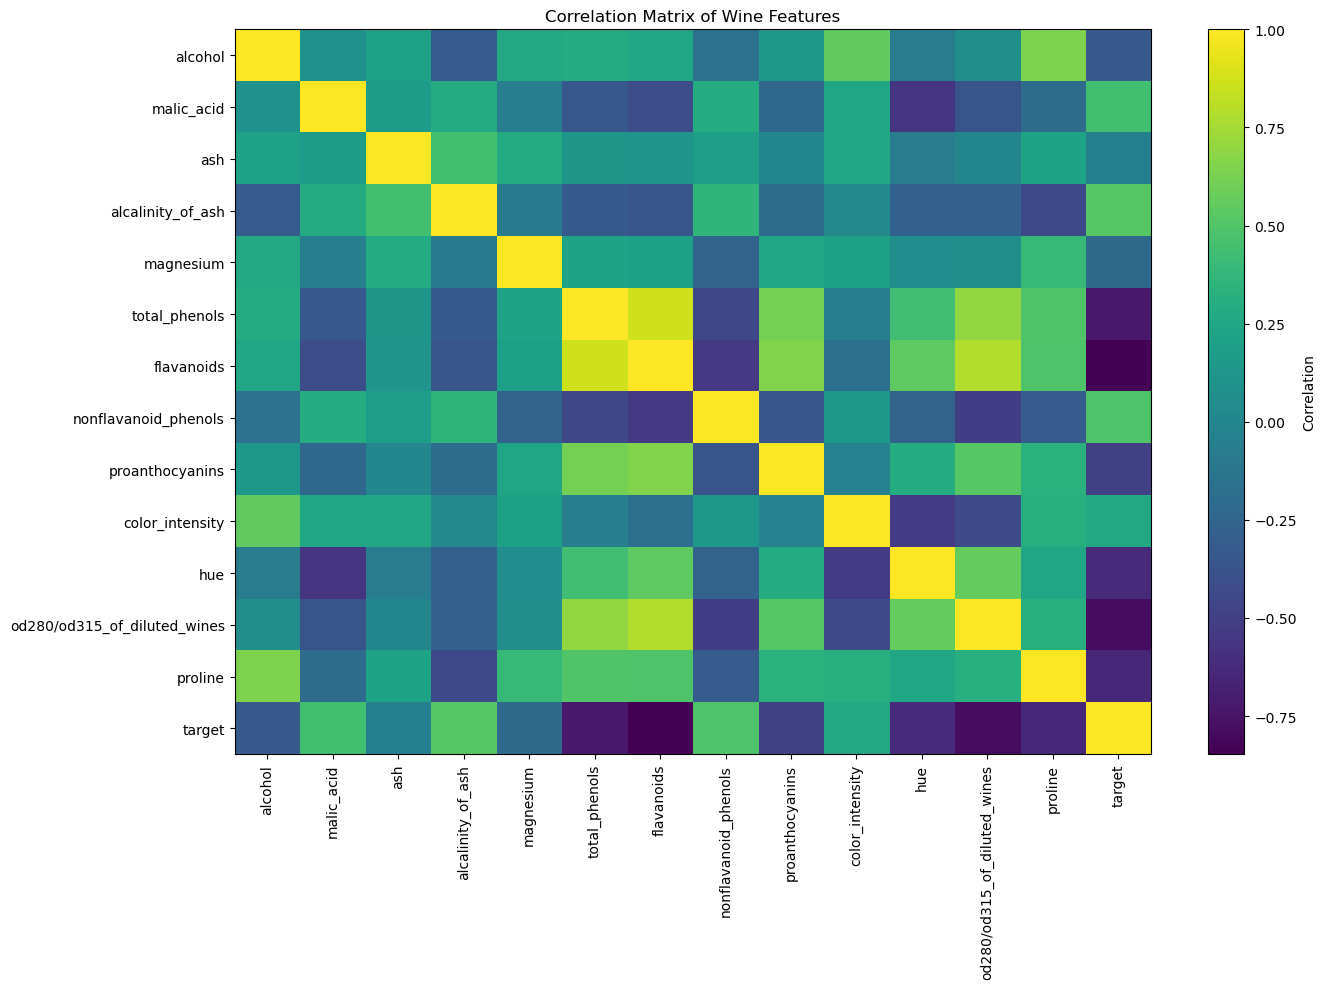

In [15]:
correlation_matrix = wine_df.corr()

plt.figure(figsize=(14, 10))
plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix of Wine Features")
plt.tight_layout()
plt.show()

<h4 style= "color: #51afe9; text-align: left; font-weight: bold;">
EDA Findings
</h4>

The exploratory analysis revealed several important characteristics of the dataset:

- The three wine classes are reasonably represented, although Class 1 contains the largest number of observations and Class 2 the smallest. There is no severe class imbalance
- The predictor variables operate on substantially different numerical scales. For example, `proline` contains values in the hundreds and thousands, while variables such as `hue` and `nonflavanoid_phenols` have much smaller values. Feature standardization will therefore be important before applying PCA and KNN
- Some features have approximately symmetric distributions, while others such as `malic_acid`, `color_intensity`, and `proline` show some positive skewness
- Alcohol levels differ across the three wine classes. Class 0 generally has higher alcohol levels, while Class 1 generally has lower values
- Proline also shows considerable differences between wine classes, particularly with Class 0 having substantially higher values than Classes 1 and 2
- The correlation matrix shows relationships among several chemical properties. In particular, features such as `total_phenols`, `flavanoids`, and `od280/od315_of_diluted_wines` appear positively related
- These correlations suggest that some features contain overlapping information, providing motivation for applying Principal Component Analysis (PCA) to reduce dimensionality while retaining as much useful variation as possible

<h3 style= "color: #51a0e9; text-align: left; font-weight: bold;">
3. Data Preparation
</h3>

<h4 style= "color: #51a2e9; text-align: left; font-weight: bold;">
3.1. Separation of Features and Target
</h4>

The predictor variables are separated from the target variable before splitting the data into training and testing sets.

In [16]:
X = wine_df.drop(columns="target")
y = wine_df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (178, 13)
Target shape: (178,)


<h4 style= "color: #51b6e9; text-align: left; font-weight: bold;">
3.2. Train-Test Split
</h4>

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (142, 13)
Testing set: (36, 13)


<h4 style= "color: #51c3e9; text-align: left; font-weight: bold;">
3.3. Standardization of Features
</h4>

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

StandardScaler was fitted only on the training data to prevent data leakage. The same transformation was then applied to the test data

Standardization is particularly important because KNN uses distances between observations and the wine features have substantially different numerical scales

<h3 style= "color:#51c3e9 ; text-align: left; font-weight: bold;">
4. PCA
</h3>

We are asking how many principal components are needed to retain approximately 95% of the information (variance) in the original standardized data?

In [19]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train_scaled)

PCA()

In [20]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

cumulative_variance

array([0.35792104, 0.55062776, 0.66082611, 0.73354887, 0.80076806,
       0.85208748, 0.89586171, 0.92087024, 0.94366454, 0.96243556,
       0.98025321, 0.99282042, 1.        ])

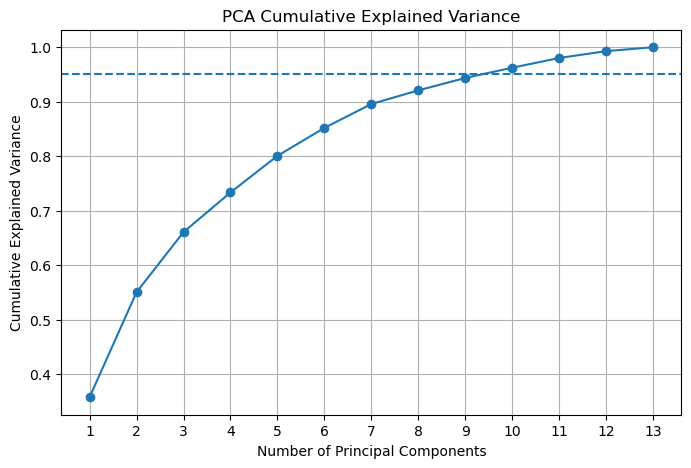

In [21]:
# visualization
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.95, linestyle="--")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid()
plt.show()

The cumulative explained variance shows how much information from the original 13 features is retained as additional principal components are included.

Approximately 95% of the variance is reached between 9 and 10 components. Therefore, 10 principal components are selected to retain at least 95% of the variance while reducing the dimensionality of the dataset from 13 features to 10 components.

In [22]:
# data transformation
pca = PCA(n_components=10)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Before PCA:", X_train_scaled.shape)
print("After PCA:", X_train_pca.shape)

Before PCA: (142, 13)
After PCA: (142, 10)


<h3 style= "color: #5190e9; text-align: left; font-weight: bold;">
5. Baseline KNN
</h3>

A baseline is fitted with default KNN settings on the PCA-transformed data. A second baseline on the scaled features without PCA is added to show whether PCA actually helps.

In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

knn = KNeighborsClassifier()

knn.fit(X_train_pca, y_train)
y_pred = knn.predict(X_test_pca)

print("Baseline Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Baseline Accuracy: 0.9722222222222222
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      0.93      0.96        14
           2       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



In [24]:
# baseline without PCA (scaled features only) for comparison
knn_nopca = KNeighborsClassifier()
knn_nopca.fit(X_train_scaled, y_train)
print("Baseline Accuracy (no PCA):", accuracy_score(y_test, knn_nopca.predict(X_test_scaled)))

Baseline Accuracy (no PCA): 0.9722222222222222


With only 36 test samples, one misclassification changes accuracy by about 2.8%, so small differences between models should not be over-interpreted.

<h4 style= "color: #5181e9; text-align: left; font-weight: bold;">
5.1. Hyperparameter Tuning
</h4>

We use a small sensible grid, instead of an unnecessarily huge search.

Scaling and PCA are placed **inside a Pipeline** so that, during cross-validation, they are re-fitted on each training fold only. Tuning on data that was already scaled and PCA-transformed on the full training set would leak information from the validation folds into the model. The number of PCA components is tuned together with the KNN parameters.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "pca__n_components": [2, 5, 8, 10, 13],
    "knn__n_neighbors": [3, 5, 7, 9],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

grid_search = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# raw (unscaled) training data: scaling and PCA happen inside the pipeline
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'knn__weights': 'uniform', 'pca__n_components': 2}
Best CV Accuracy: 0.9790640394088669


<h4 style= "color: #519de9; text-align: left; font-weight: bold;">
5.2. Tuned Model Evaluation
</h4>

In [26]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Tuned Test Accuracy:", accuracy_score(y_test, y_pred_tuned))
print(classification_report(y_test, y_pred_tuned))

Tuned Test Accuracy: 0.9444444444444444
              precision    recall  f1-score   support

           0       0.92      0.92      0.92        12
           1       0.93      0.93      0.93        14
           2       1.00      1.00      1.00        10

    accuracy                           0.94        36
   macro avg       0.95      0.95      0.95        36
weighted avg       0.94      0.94      0.94        36



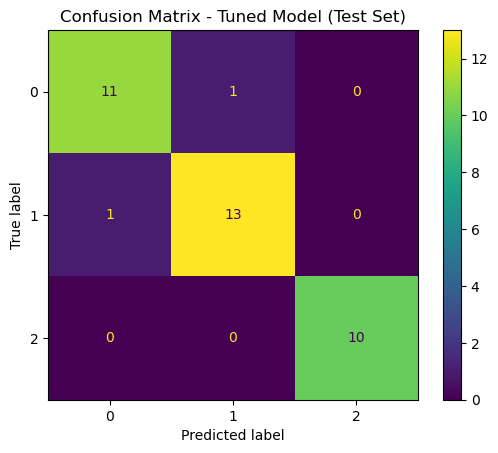

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned)
plt.title("Confusion Matrix - Tuned Model (Test Set)")
plt.show()

In [28]:
# more robust estimate than a single 36-sample test split
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scores = cross_val_score(best_model, X, y, cv=rskf, scoring="accuracy")
print(f"Repeated CV accuracy: {scores.mean():.3f} +/- {scores.std():.3f}")

Repeated CV accuracy: 0.964 +/- 0.029


The baseline KNN model was compared with a model optimized using GridSearchCV. GridSearchCV tested different values for the number of neighbors, weighting method, and distance metric using 5-fold cross-validation, together with the number of PCA components. Because scaling and PCA are inside the pipeline, the cross-validation scores are free of data leakage. The confusion matrix shows which classes, if any, are confused, and the repeated cross-validation gives a more stable performance estimate than the small test set alone.

<h4 style= "color: #51b1e9; text-align: left; font-weight: bold;">
Conclusion
</h4>

The baseline KNN model on 10 principal components achieved a test accuracy of approximately 97.2%, identical to a KNN trained on the scaled features without PCA. The tuned pipeline (scaling, PCA and KNN tuned together with 5-fold cross-validation) selected 2 principal components, 7 neighbors, Euclidean distance and uniform weighting, with a cross-validation accuracy of approximately 97.9%

On the held-out test set the tuned model reached approximately 94.4% accuracy (2 of 36 wines misclassified, both between Classes 0 and 1). Repeated stratified cross-validation gives about 96.4% (+/- 2.9%), which is the more reliable estimate of real-world performance

Earlier versions of this analysis reported 100% test accuracy after tuning on pre-transformed data. That figure came from a single small test split and from tuning outside a pipeline, so it should not be taken as the expected performance. With only 36 test samples, differences of one or two wines between models are within noise: all configurations perform at roughly 94-98%

Overall, the model classifies the three wine classes well (about 96% accuracy), meeting the business need for automated classification, although the test accuracy is marginally below the 95% target. Predictions near class boundaries should still be reviewed by an expert, and the model should be validated on more data before deployment